# 상관분석
- 금, 은, 달러의 상관성 분석

In [ ]:
# 필요한 패키지 설치
# uv add openpyxl

In [2]:
import pandas as pd
df = pd.read_excel("datas2/일별_금은달러.xlsx")

In [3]:
df.head()

,일자,금값,은값,달러 환율
0,2020.08.07,78538.90,27.53,1188.5
1,2020.08.06,78009.22,28.39,1185.5
2,2020.08.05,77748.00,26.88,1188.0
3,2020.08.04,75873.57,26.01,1194.5
4,2020.08.03,75761.76,24.39,1195.7


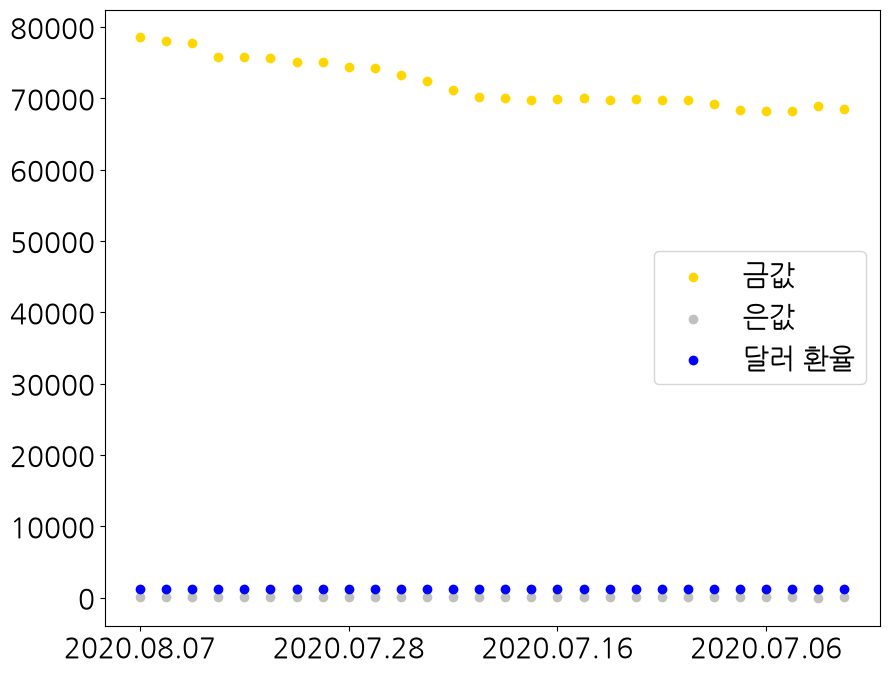

In [4]:
# 그래프 기본 설정
from matplotlib import pyplot as plt
import numpy as np

# plt.rcParams["font.family"] = 'Malgun Gothic'  # 윈도우 환경
plt.rcParams["font.family"] = 'NanumGothic'      # WSL ubuntu 환경
plt.rcParams['axes.unicode_minus'] = False

plt.rcParams["font.size"] = 20
plt.rcParams["figure.figsize"] = (10, 8)

plt.scatter(df['일자'], df['금값'], label = '금값', color = 'gold')
plt.scatter(df['일자'], df['은값'], label = '은값', color = 'silver')
plt.scatter(df['일자'], df['달러 환율'], label = '달러 환율', color = 'blue')
plt.xticks(df['일자'].iloc[::8])
plt.legend()
plt.show()

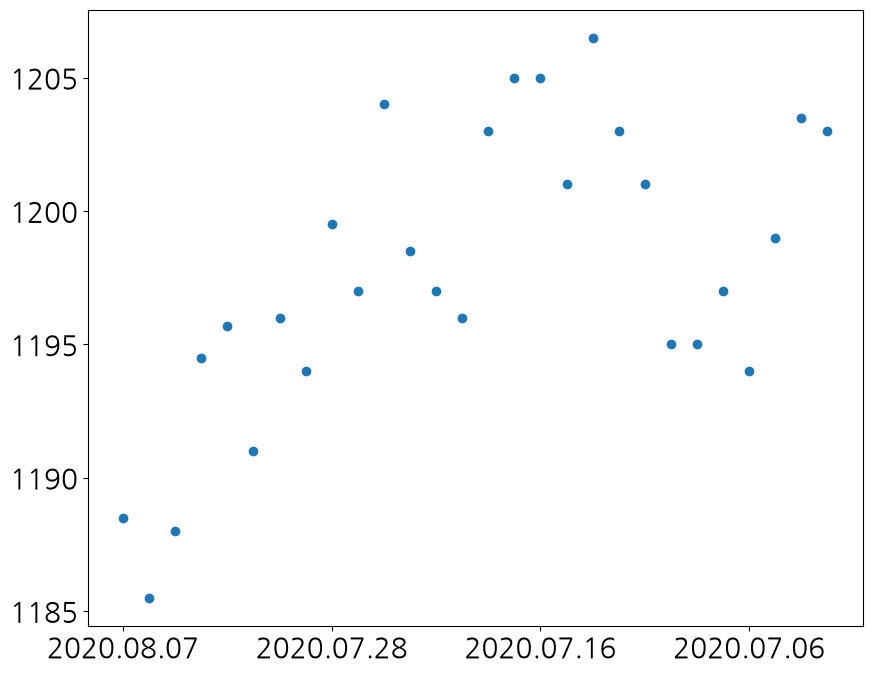

In [5]:
# plt.scatter(df['일자'], df['금값'])
# plt.scatter(df['일자'], df['은값'])
plt.scatter(df['일자'], df['달러 환율'])
plt.xticks(df['일자'].iloc[::8])
plt.show()

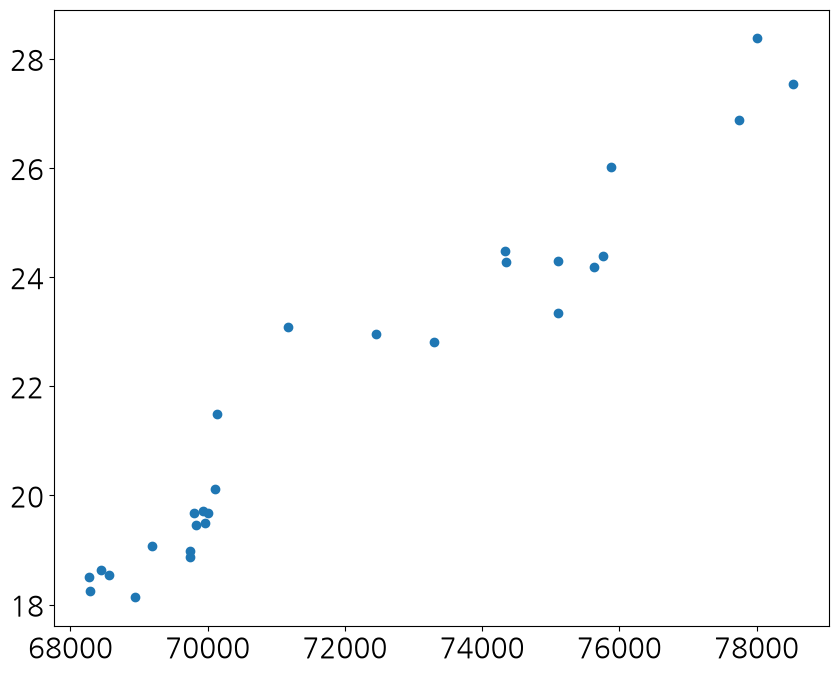

In [6]:
# 금값과 은값의 산점도
plt.scatter(df['금값'], df['은값'])
plt.show()

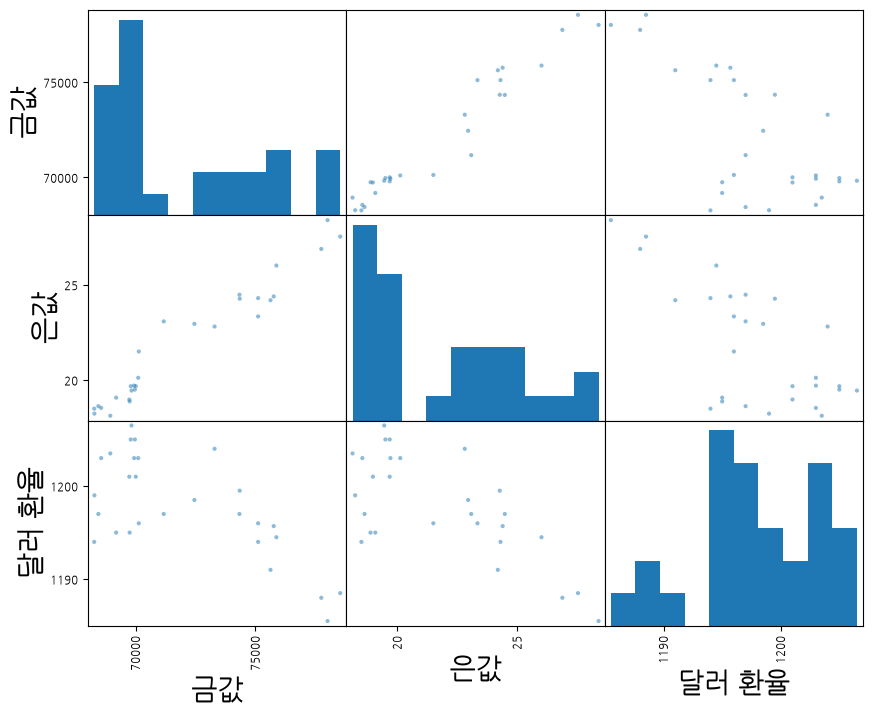

In [7]:
# scatter matirx
pd.plotting.scatter_matrix(df.drop('일자', axis = 1))
plt.show()

## 피어슨 상관계수

In [8]:
from scipy import stats
print(stats.pearsonr(df['금값'], df['은값']))
print(stats.pearsonr(df['금값'], df['달러 환율']))
print(stats.pearsonr(df['은값'], df['달러 환율']))

PearsonRResult(statistic=np.float64(0.9718640116033495), pvalue=np.float64(7.508878356557701e-18))
PearsonRResult(statistic=np.float64(-0.6793266264341936), pvalue=np.float64(7.033325258452313e-05))
PearsonRResult(statistic=np.float64(-0.6954569556203561), pvalue=np.float64(3.989042061957927e-05))


- [해석]
    - 금값, 은값 : 강력한 양의 상관관계
    - 금값, 달러 : 음의 상관계
    - 은값, 달러 : 음의 상관계

- 피어슨 상관계수 보기 좋게 출력

In [9]:
import itertools
target_columns = ['금값', '은값', '달러 환율']
for col1, col2 in itertools.combinations(target_columns, 2):
    result = stats.pearsonr(df[col1], df[col2])
    print("{} ~ {}: coef:{}, p-value: {}".format(col1, col2, result[0], result[1]))

금값 ~ 은값: coef:0.9718640116033495, p-value: 7.508878356557701e-18
금값 ~ 달러 환율: coef:-0.6793266264341936, p-value: 7.033325258452313e-05
은값 ~ 달러 환율: coef:-0.6954569556203561, p-value: 3.989042061957927e-05


## 스피어만 상관계수

In [10]:
import itertools
target_columns = ['금값', '은값', '달러 환율']

# 2개씩 조합해서 순서대로 넘겨주는 것
for col1, col2 in itertools.combinations(target_columns, 2):
    result = stats.spearmanr(df[col1], df[col2])
    print("{} ~ {}: coef:{}, p-value: {}".format(col1, col2, result[0], result[1]))

금값 ~ 은값: coef:0.9711235892228813, p-value: 1.0481280432981477e-17
금값 ~ 달러 환율: coef:-0.5039075855936102, p-value: 0.006257468267109452
은값 ~ 달러 환율: coef:-0.528106006718531, p-value: 0.003869997604824082


- [해석]
    - 금과 은은 매우 강한 양의 상관관계
    - 금/은과 환율은 유의미한 음의 상관관계

## 컬럼간 상관계수 계산

In [11]:
df.head()

,일자,금값,은값,달러 환율
0,2020.08.07,78538.90,27.53,1188.5
1,2020.08.06,78009.22,28.39,1185.5
2,2020.08.05,77748.00,26.88,1188.0
3,2020.08.04,75873.57,26.01,1194.5
4,2020.08.03,75761.76,24.39,1195.7


In [12]:
df.drop('일자', axis = 1).corr(method = 'pearson')

,금값,은값,달러 환율
금값,1.000000,0.971864,-0.679327
은값,0.971864,1.000000,-0.695457
달러 환율,-0.679327,-0.695457,1.000000


In [13]:
df.drop('일자', axis = 1).corr(method = 'spearman')

,금값,은값,달러 환율
금값,1.000000,0.971124,-0.503908
은값,0.971124,1.000000,-0.528106
달러 환율,-0.503908,-0.528106,1.000000
